# Práctica: **Overfitting → Regularización** y **Optimizadores**

El parcial cubre *hasta optimización y regularización*. Este cuadernillo es el "lunes forzado":
1. Entrenar un modelo **hasta que haga overfitting** (ver la señal en las curvas).
2. Arreglarlo con **weight_decay (L2)**, **dropout**, **early stopping** y **BatchNorm**.
3. Comparar **SGD / momentum / RMSProp / Adam**.
4. Probar **learning rate scheduling**.

Vamos a usar un **subconjunto pequeño** de MNIST a propósito: pocos datos → mucho overfitting → se ve claro.


## 0. Dataset pequeño

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision
from sklearn.metrics import accuracy_score

torch.manual_seed(0); np.random.seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

Dispositivo: cuda


In [2]:
trainset = torchvision.datasets.MNIST(root='./data', train=True, download=True)
testset = torchvision.datasets.MNIST(root='./data', train=False, download=True)
Xall = np.stack([np.asarray(img, dtype=np.float32).reshape(-1) for img, _ in trainset]) / 255.
yall = np.array([l for _, l in trainset], dtype=np.int64)
Xtest = np.stack([np.asarray(img, dtype=np.float32).reshape(-1) for img, _ in testset]) / 255.
ytest = np.array([l for _, l in testset], dtype=np.int64)

# subconjunto CHICO a propósito (para ver overfitting rápido)
ix = np.random.RandomState(0).permutation(len(Xall))
X_train, y_train = Xall[ix[:800]], yall[ix[:800]]
X_val,   y_val   = Xall[ix[800:1400]], yall[ix[800:1400]]
print(f"Train: {X_train.shape[0]} | Val: {X_val.shape[0]} | Test completo: {Xtest.shape[0]}")

Train: 800 | Val: 600 | Test completo: 10000


Clase `Dataset` y `DataLoader` (igual que siempre):

In [3]:
class Dataset(torch.utils.data.Dataset):
    def __init__(self, X, Y):
        self.X = torch.from_numpy(X).float().to(device)
        self.Y = torch.from_numpy(Y).long().to(device)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, ix):
        return self.X[ix], self.Y[ix]

def hacer_dataloaders(ds_tr, ds_va, bs=64):
    return {
        'train': torch.utils.data.DataLoader(ds_tr, batch_size=bs, shuffle=True),
        'val': torch.utils.data.DataLoader(ds_va, batch_size=200, shuffle=False),
    }

dataloader = hacer_dataloaders(Dataset(X_train, y_train), Dataset(X_val, y_val))

La **función `fit`** generalizada (acepta `scheduler` y `early_stopping`):

In [4]:
def softmax(x):
    return torch.exp(x) / torch.exp(x).sum(axis=-1, keepdims=True)

def fit(model, dataloader, optimizer, scheduler=None, epochs=50, log_each=10,
        early_stopping=0, verbose=1):
    criterion = torch.nn.CrossEntropyLoss()
    l, acc, val_l, val_acc, lr = [], [], [], [], []
    best_acc, steps = 0, 0
    for e in range(1, epochs + 1):
        for g in optimizer.param_groups:
            lr.append(g['lr'])
        model.train()
        _l, _acc = [], []
        for x_b, y_b in dataloader['train']:
            y_pred = model(x_b)
            loss = criterion(y_pred, y_b)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            _l.append(loss.item())
            _acc.append(accuracy_score(y_b.cpu().numpy(), torch.argmax(softmax(y_pred), axis=1).cpu().detach().numpy()))
        l.append(np.mean(_l)); acc.append(np.mean(_acc))
        model.eval()
        _vl, _vacc = [], []
        with torch.no_grad():
            for x_b, y_b in dataloader['val']:
                y_pred = model(x_b)
                _vl.append(criterion(y_pred, y_b).item())
                _vacc.append(accuracy_score(y_b.cpu().numpy(), torch.argmax(softmax(y_pred), axis=1).cpu().numpy()))
        val_l.append(np.mean(_vl)); val_acc.append(np.mean(_vacc))
        if val_acc[-1] > best_acc:
            best_acc = val_acc[-1]; steps = 0
            torch.save(model.state_dict(), 'ckpt_opt.pt')
        else:
            steps += 1
        if scheduler: scheduler.step()
        if early_stopping and steps > early_stopping:
            print(f"Early stop en epoch {e} (val no mejora hace {early_stopping+1})"); break
        if not e % log_each and verbose:
            print(f"Epoch {e}/{epochs} loss {l[-1]:.4f} acc {acc[-1]:.4f} val_acc {val_acc[-1]:.4f}")
    model.load_state_dict(torch.load('ckpt_opt.pt', weights_only=True))
    return {'loss': l, 'acc': acc, 'val_loss': val_l, 'val_acc': val_acc, 'lr': lr}

## 1. Sobreajuste (baseline): MUCHA capacidad, SIN regularización

Señal de **overfitting**: `acc` de train sigue subiendo (llega a ~1.0) mientras que `val_acc` se estanca o baja. El modelo está *memorizando* el train. 

In [5]:
def build_model(H=200, dropout=0.0, use_bn=False):
    layers = [torch.nn.Linear(784, H), torch.nn.ReLU()]
    if use_bn: layers.insert(-1, torch.nn.BatchNorm1d(H))
    layers += [torch.nn.Linear(H, H), torch.nn.ReLU()]
    if use_bn: layers.insert(-1, torch.nn.BatchNorm1d(H))
    if dropout > 0:
        layers += [torch.nn.Dropout(p=dropout)]
    layers += [torch.nn.Linear(H, 10)]
    return torch.nn.Sequential(*layers).to(device)

model = build_model(dropout=0.0)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
hist_base = fit(model, dataloader, optimizer, epochs=120, log_each=20)

Epoch 20/120 loss 0.0157 acc 1.0000 val_acc 0.8650


Epoch 40/120 loss 0.0025 acc 1.0000 val_acc 0.8700


Epoch 60/120 loss 0.0010 acc 1.0000 val_acc 0.8667


Epoch 80/120 loss 0.0005 acc 1.0000 val_acc 0.8650


Epoch 100/120 loss 0.0003 acc 1.0000 val_acc 0.8667


Epoch 120/120 loss 0.0002 acc 1.0000 val_acc 0.8667


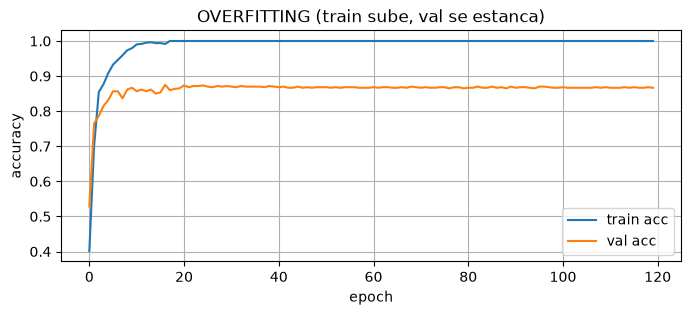

In [6]:
plt.figure(figsize=(8, 3))
plt.plot(hist_base['acc'], label='train acc')
plt.plot(hist_base['val_acc'], label='val acc')
plt.xlabel('epoch'); plt.ylabel('accuracy'); plt.title('OVERFITTING (train sube, val se estanca)')
plt.legend(); plt.grid(); plt.show()

## 2. Regularización L2 (weight_decay)

Se suma ∥w∥² a la pérdida para forzar pesos pequeños. En PyTorch se activa con el parámetro **`weight_decay`** del optimizador (valores típicos 0.001 - 0.01).

In [7]:
model = build_model(dropout=0.0)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=0.01)
hist_wd = fit(model, dataloader, optimizer, epochs=120, log_each=20)

Epoch 20/120 loss 0.1360 acc 0.9832 val_acc 0.8683


Epoch 40/120 loss 0.1043 acc 0.9916 val_acc 0.8583


Epoch 60/120 loss 0.0877 acc 0.9964 val_acc 0.8633


Epoch 80/120 loss 0.0766 acc 0.9976 val_acc 0.8650


Epoch 100/120 loss 0.0709 acc 0.9988 val_acc 0.8883


Epoch 120/120 loss 0.0735 acc 0.9988 val_acc 0.8683


## 3. Dropout

Apaga neuronas al azar durante el entrenamiento (forzando caminos alternativos). Capa `torch.nn.Dropout(p=...)`. **Ojo**: en `model.eval()` el dropout se desactiva solo.

In [8]:
model = build_model(dropout=0.2)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
hist_do = fit(model, dataloader, optimizer, epochs=120, log_each=20)

Epoch 20/120 loss 0.0287 acc 0.9940 val_acc 0.8767


Epoch 40/120 loss 0.0032 acc 1.0000 val_acc 0.8767


Epoch 60/120 loss 0.0012 acc 1.0000 val_acc 0.8750


Epoch 80/120 loss 0.0013 acc 1.0000 val_acc 0.8800


Epoch 100/120 loss 0.0006 acc 1.0000 val_acc 0.8733


Epoch 120/120 loss 0.0004 acc 1.0000 val_acc 0.8817


## 4. Comparación + BatchNorm + Early Stopping

`BatchNorm` normaliza las activaciones de la capa oculta (acelera muchísimo el entrenamiento). Y activamos `early_stopping` para quedarnos con el mejor modelo y cortar a tiempo.

In [9]:
model = build_model(use_bn=True)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
hist_bn = fit(model, dataloader, optimizer, epochs=120, log_each=20, early_stopping=15)

Epoch 20/120 loss 0.0059 acc 1.0000 val_acc 0.8900
Early stop en epoch 22 (val no mejora hace 16)


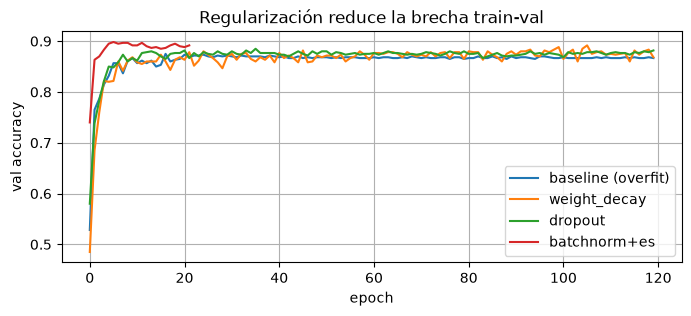

In [10]:
plt.figure(figsize=(8, 3))
for name, h in [('baseline (overfit)', hist_base), ('weight_decay', hist_wd),
                ('dropout', hist_do), ('batchnorm+es', hist_bn)]:
    plt.plot(h['val_acc'], label=name)
plt.xlabel('epoch'); plt.ylabel('val accuracy'); plt.legend(); plt.grid()
plt.title('Regularización reduce la brecha train-val')
plt.show()

## 5. Optimizadores: SGD vs momentum vs RMSProp vs Adam

Las variantes son más rápidas porque cada una mejora el descenso: *momentum* acumula inercia, *RMSProp* adapta el paso por parámetro, *Adam* combina ambos → práctica recomendada: **empezar con Adam lr=0.001**.

In [11]:
optimizers = {
    'SGD':      lambda: torch.optim.SGD(model.parameters(), lr=0.01),
    'SGD+mon':  lambda: torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9),
    'RMSProp':  lambda: torch.optim.RMSprop(model.parameters(), lr=0.001),
    'Adam':     lambda: torch.optim.Adam(model.parameters(), lr=0.001),
}
hists = {}
for name, build_opt in optimizers.items():
    model = build_model(H=128, dropout=0.0)
    hists[name] = fit(model, dataloader, build_opt(), epochs=20, log_each=5, verbose=0)
    print(f"{name}: loss final {hists[name]['loss'][-1]:.4f} | val_acc {hists[name]['val_acc'][-1]:.4f}")

SGD: loss final 2.1181 | val_acc 0.3233


SGD+mon: loss final 0.2007 | val_acc 0.8433


RMSProp: loss final 0.0157 | val_acc 0.8650


Adam: loss final 0.0293 | val_acc 0.8617


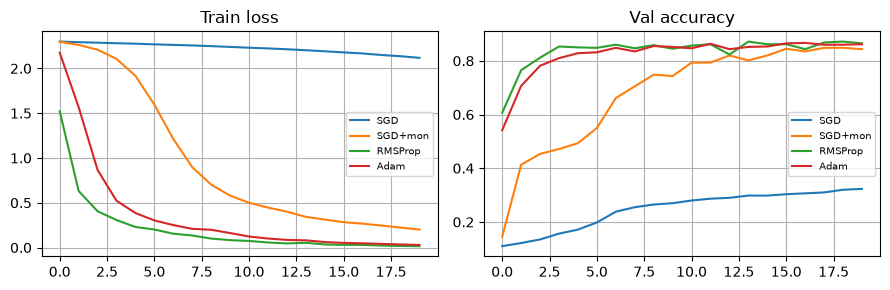

In [12]:
plt.figure(figsize=(9, 3))
ax = plt.subplot(121)
for name, h in hists.items():
    ax.plot(h['loss'], label=name)
ax.set_title('Train loss'); ax.legend(fontsize=7); ax.grid()
ax = plt.subplot(122)
for name, h in hists.items():
    ax.plot(h['val_acc'], label=name)
ax.set_title('Val accuracy'); ax.legend(fontsize=7); ax.grid()
plt.tight_layout(); plt.show()

## 6. Learning Rate Scheduling

Variar el learning rate durante el entrenamiento. **StepLR** lo multiplica por `gamma` cada `step_size` epochs. **CyclicLR** lo sube y lo baja cíclicamente.

In [13]:
model = build_model(H=128, dropout=0.0)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
sched = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
hist_step = fit(model, dataloader, optimizer, scheduler=sched, epochs=30, verbose=0)
print(f"StepLR val_acc final {hist_step['val_acc'][-1]:.4f}")

StepLR val_acc final 0.8900


In [14]:
model = build_model(H=128, dropout=0.0)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
sched = torch.optim.lr_scheduler.CyclicLR(optimizer, base_lr=0.0001, max_lr=0.01,
                                          step_size_up=5, step_size_down=25)
hist_cyc = fit(model, dataloader, optimizer, scheduler=sched, epochs=30, verbose=0)
print(f"CyclicLR val_acc final {hist_cyc['val_acc'][-1]:.4f}")

CyclicLR val_acc final 0.8883


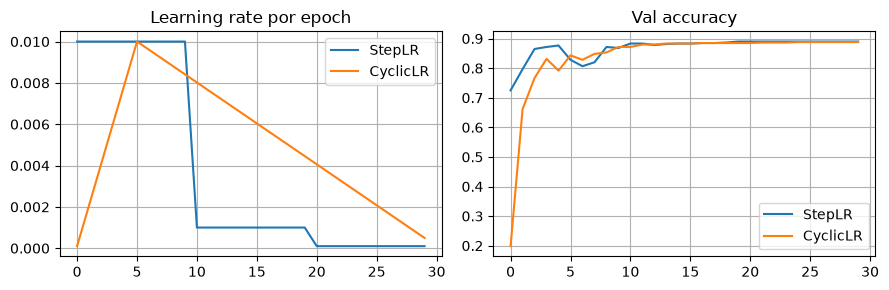

In [15]:
plt.figure(figsize=(9, 3))
ax = plt.subplot(121)
ax.plot(hist_step['lr'], label='StepLR'); ax.plot(hist_cyc['lr'], label='CyclicLR')
ax.set_title('Learning rate por epoch'); ax.legend(); ax.grid()
ax = plt.subplot(122)
ax.plot(hist_step['val_acc'], label='StepLR'); ax.plot(hist_cyc['val_acc'], label='CyclicLR')
ax.set_title('Val accuracy'); ax.legend(); ax.grid()
plt.tight_layout(); plt.show()

## Recapitulación (preguntas típicas del parcial)

1. **¿Cómo detectás overfitting?** En las curvas: train sigue mejorando, val se estanca/baja.
2. **¿Qué técnicas de regularización viste?** L2/weight_decay, dropout, early stopping, más datos, data augmentation, batch norm.
3. **¿Qué optimizadores y cuál usar de entrada?** SGD, SGD+momentum, RMSProp, Adam → **Adam lr=0.001**.
4. **¿Qué es un scheduler y para qué?** Variar el lr durante el entrenamiento (p.ej. StepLR, CyclicLR).
5. **model.train() vs model.eval()?** Activa/desactiva capas con comportamiento distinto (Dropout, BatchNorm). Olvidarse de esto es una fuente clásica de errores en el examen.
